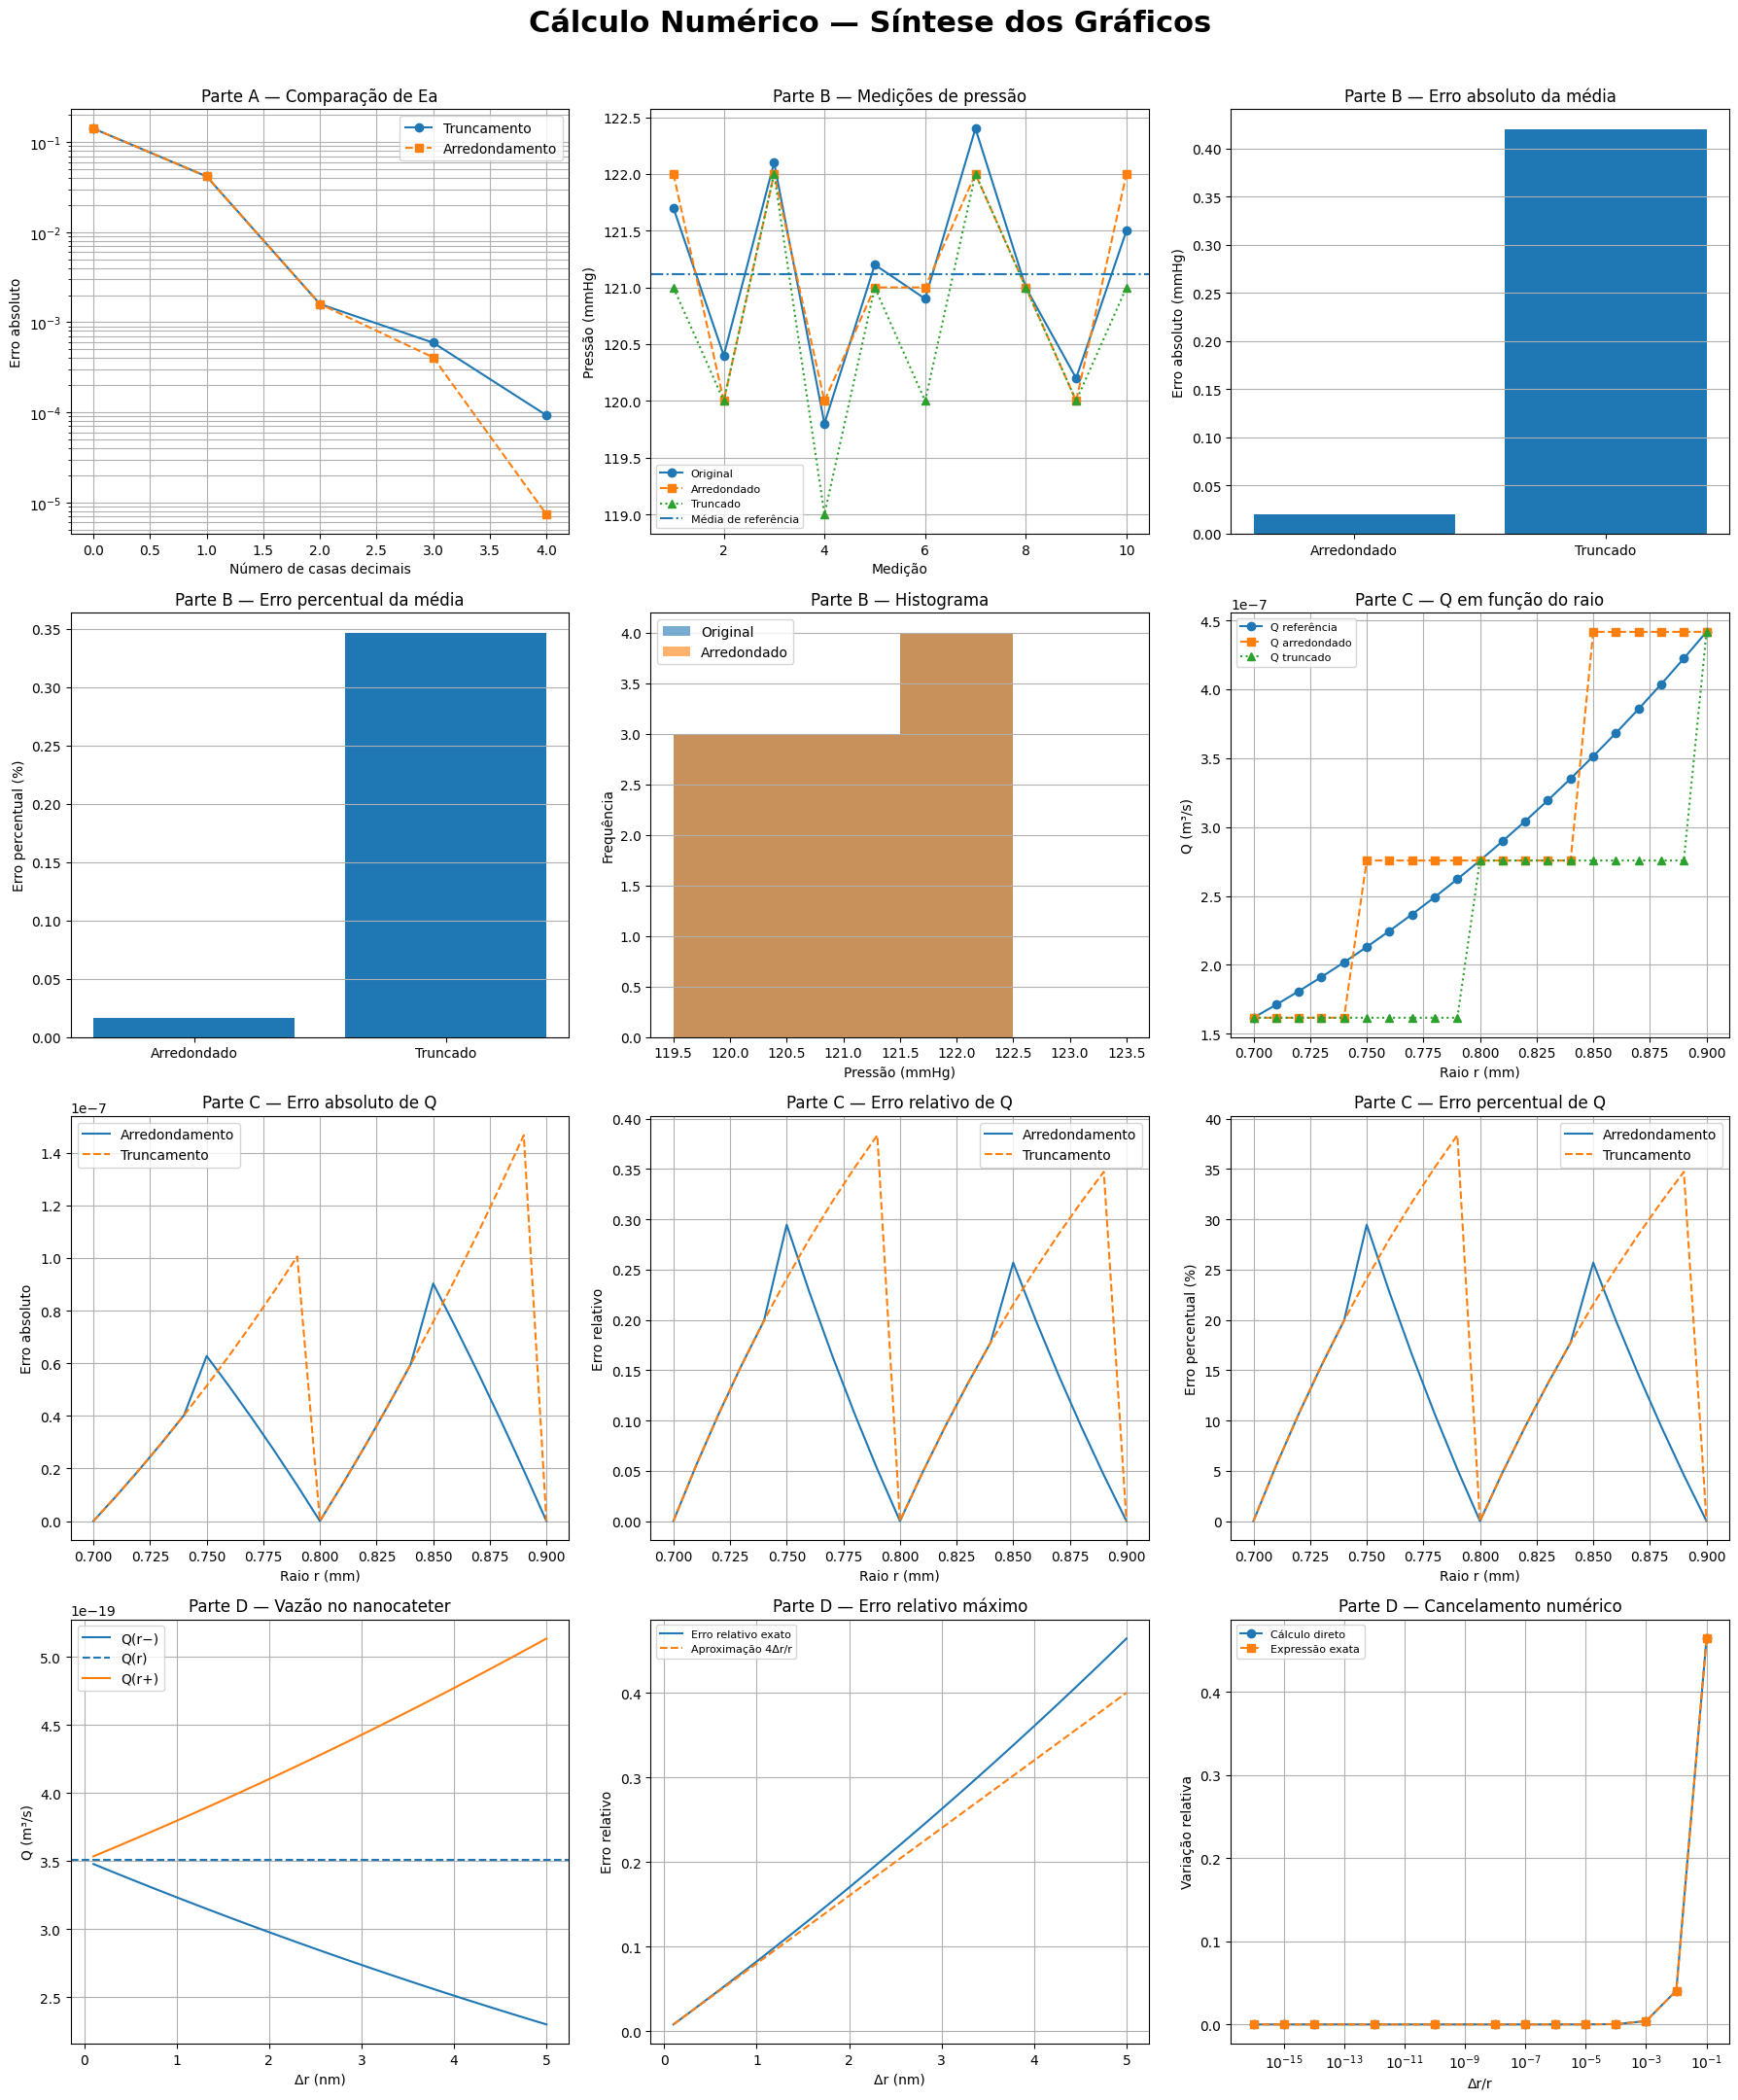

Quadro gerado com sucesso!
Arquivo: quadro_todos_os_graficos.png


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FUNÇÕES
# ============================================================

def vazao(r, mu, dp, L):
    return math.pi * r**4 * dp / (8 * mu * L)

def truncar(x, n):
    fator = 10**n
    return math.trunc(x * fator) / fator

def arredondar(x, n):
    fator = 10**n
    return math.floor(x * fator + 0.5) / fator


# ============================================================
# PARTE A — TRUNCAMENTO E ARREDONDAMENTO
# ============================================================

x1 = 3.14159265

n = np.arange(5)

Ea_trunc_A = [
    abs(x1 - truncar(x1, int(i)))
    for i in n
]

Ea_arred_A = [
    abs(x1 - arredondar(x1, int(i)))
    for i in n
]


# ============================================================
# PARTE B — PRESSÃO ARTERIAL
# ============================================================

pressao = np.array([
    121.7, 120.4, 122.1, 119.8, 121.2,
    120.9, 122.4, 121.0, 120.2, 121.5
])

pressao_arred = np.floor(pressao + 0.5)
pressao_trunc = np.trunc(pressao)

media_ref = pressao.mean()

x = np.arange(1, 11)

media_arred = pressao_arred.mean()
media_trunc = pressao_trunc.mean()

Ea_arred_B = abs(media_ref - media_arred)
Ea_trunc_B = abs(media_ref - media_trunc)

Ep_arred_B = 100 * Ea_arred_B / abs(media_ref)
Ep_trunc_B = 100 * Ea_trunc_B / abs(media_ref)


# ============================================================
# PARTE C — VAZÃO NO TUBO
# ============================================================

rC = 0.80e-3
LC = 0.20
muC = 3.5e-3
dpC = 1200

QC = vazao(rC, muC, dpC, LC)

# Variação do raio
raios_mm = np.round(
    np.arange(0.70, 0.90 + 0.001, 0.01), 2
)

Q_referencia = np.array([
    vazao(rr * 1e-3, muC, dpC, LC)
    for rr in raios_mm
])

# Raio arredondado e truncado
raios_arred = np.array([
    arredondar(float(rr), 1)
    for rr in raios_mm
])

raios_trunc = np.array([
    truncar(float(rr), 1)
    for rr in raios_mm
])

Q_arred = np.array([
    vazao(rr * 1e-3, muC, dpC, LC)
    for rr in raios_arred
])

Q_trunc = np.array([
    vazao(rr * 1e-3, muC, dpC, LC)
    for rr in raios_trunc
])

# Erros
Ea_arred_C = np.abs(Q_referencia - Q_arred)
Ea_trunc_C = np.abs(Q_referencia - Q_trunc)

Er_arred_C = Ea_arred_C / np.abs(Q_referencia)
Er_trunc_C = Ea_trunc_C / np.abs(Q_referencia)

Ep_arred_C = 100 * Er_arred_C
Ep_trunc_C = 100 * Er_trunc_C


# ============================================================
# PARTE D — NANOCATETER
# ============================================================

rD = 50e-9
LD = 10e-6
muD = 3.5e-3
dpD = 5000

QD = vazao(rD, muD, dpD, LD)

# Variação do raio
delta_r_nm = np.round(
    np.arange(0.1, 5.0 + 0.001, 0.1), 1
)

r_minus = (50 - delta_r_nm) * 1e-9
r_plus = (50 + delta_r_nm) * 1e-9

Q_minus = np.array([
    vazao(rr, muD, dpD, LD)
    for rr in r_minus
])

Q_plus = np.array([
    vazao(rr, muD, dpD, LD)
    for rr in r_plus
])

Ea_minus = np.abs(Q_minus - QD)
Ea_plus = np.abs(Q_plus - QD)

Ea_max = np.maximum(Ea_minus, Ea_plus)

Er_minus = Ea_minus / abs(QD)
Er_plus = Ea_plus / abs(QD)

Er_max = np.maximum(Er_minus, Er_plus)

Epercent_max = 100 * Er_max

aproximacao_linear = 4 * delta_r_nm / 50


# ============================================================
# PRECISÃO FLOAT32 E FLOAT64
# ============================================================

def vazao_numpy(r, dtype):
    rr = dtype(r)
    mm = dtype(muD)
    dd = dtype(dpD)
    ll = dtype(LD)

    return (
        dtype(np.pi) * rr**dtype(4) * dd
        / (dtype(8) * mm * ll)
    )

Q32 = vazao_numpy(rD, np.float32)
Q64 = vazao_numpy(rD, np.float64)


# ============================================================
# CANCELAMENTO NUMÉRICO
# ============================================================

razoes = np.array([
    1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6,
    1e-7, 1e-8, 1e-10, 1e-12, 1e-14,
    1e-15, 1e-16
])

delta1 = []
delta2 = []

for razao in razoes:

    r_variado = rD * (1 + razao)

    Q1 = vazao_numpy(r_variado, np.float64)
    Q0 = vazao_numpy(rD, np.float64)

    d1 = (Q1 - Q0) / Q0
    d2 = (1 + razao)**4 - 1

    delta1.append(float(d1))
    delta2.append(float(d2))


# ============================================================
# CRIAÇÃO DO QUADRO
# ============================================================

fig, axs = plt.subplots(
    4, 3,
    figsize=(18, 22)
)

fig.suptitle(
    "Cálculo Numérico — Síntese dos Gráficos",
    fontsize=22,
    fontweight="bold"
)


# ============================================================
# GRÁFICO 1 — PARTE A
# ============================================================

ax = axs[0, 0]

ax.semilogy(
    n,
    Ea_trunc_A,
    marker="o",
    label="Truncamento"
)

ax.semilogy(
    n,
    Ea_arred_A,
    marker="s",
    linestyle="--",
    label="Arredondamento"
)

ax.set_title("Parte A — Comparação de Ea")
ax.set_xlabel("Número de casas decimais")
ax.set_ylabel("Erro absoluto")
ax.grid(True, which="both")
ax.legend()


# ============================================================
# GRÁFICO 2 — PARTE B
# ============================================================

ax = axs[0, 1]

ax.plot(
    x,
    pressao,
    marker="o",
    label="Original"
)

ax.plot(
    x,
    pressao_arred,
    marker="s",
    linestyle="--",
    label="Arredondado"
)

ax.plot(
    x,
    pressao_trunc,
    marker="^",
    linestyle=":",
    label="Truncado"
)

ax.axhline(
    media_ref,
    linestyle="-.",
    label="Média de referência"
)

ax.set_title("Parte B — Medições de pressão")
ax.set_xlabel("Medição")
ax.set_ylabel("Pressão (mmHg)")
ax.grid(True)
ax.legend(fontsize=8)


# ============================================================
# GRÁFICO 3 — PARTE B
# ============================================================

ax = axs[0, 2]

ax.bar(
    ["Arredondado", "Truncado"],
    [Ea_arred_B, Ea_trunc_B]
)

ax.set_title("Parte B — Erro absoluto da média")
ax.set_ylabel("Erro absoluto (mmHg)")
ax.grid(axis="y")


# ============================================================
# GRÁFICO 4 — PARTE B
# ============================================================

ax = axs[1, 0]

ax.bar(
    ["Arredondado", "Truncado"],
    [Ep_arred_B, Ep_trunc_B]
)

ax.set_title("Parte B — Erro percentual da média")
ax.set_ylabel("Erro percentual (%)")
ax.grid(axis="y")


# ============================================================
# GRÁFICO 5 — PARTE B
# ============================================================

ax = axs[1, 1]

bins = np.arange(119.5, 123.6, 1)

ax.hist(
    pressao,
    bins=bins,
    alpha=0.6,
    label="Original"
)

ax.hist(
    pressao_arred,
    bins=bins,
    alpha=0.6,
    label="Arredondado"
)

ax.set_title("Parte B — Histograma")
ax.set_xlabel("Pressão (mmHg)")
ax.set_ylabel("Frequência")
ax.grid(axis="y")
ax.legend()


# ============================================================
# GRÁFICO 6 — PARTE C
# ============================================================

ax = axs[1, 2]

ax.plot(
    raios_mm,
    Q_referencia,
    marker="o",
    label="Q referência"
)

ax.plot(
    raios_mm,
    Q_arred,
    marker="s",
    linestyle="--",
    label="Q arredondado"
)

ax.plot(
    raios_mm,
    Q_trunc,
    marker="^",
    linestyle=":",
    label="Q truncado"
)

ax.set_title("Parte C — Q em função do raio")
ax.set_xlabel("Raio r (mm)")
ax.set_ylabel("Q (m³/s)")
ax.grid(True)
ax.legend(fontsize=8)


# ============================================================
# GRÁFICO 7 — PARTE C
# ============================================================

ax = axs[2, 0]

ax.plot(
    raios_mm,
    Ea_arred_C,
    label="Arredondamento"
)

ax.plot(
    raios_mm,
    Ea_trunc_C,
    linestyle="--",
    label="Truncamento"
)

ax.set_title("Parte C — Erro absoluto de Q")
ax.set_xlabel("Raio r (mm)")
ax.set_ylabel("Erro absoluto")
ax.grid(True)
ax.legend()


# ============================================================
# GRÁFICO 8 — PARTE C
# ============================================================

ax = axs[2, 1]

ax.plot(
    raios_mm,
    Er_arred_C,
    label="Arredondamento"
)

ax.plot(
    raios_mm,
    Er_trunc_C,
    linestyle="--",
    label="Truncamento"
)

ax.set_title("Parte C — Erro relativo de Q")
ax.set_xlabel("Raio r (mm)")
ax.set_ylabel("Erro relativo")
ax.grid(True)
ax.legend()


# ============================================================
# GRÁFICO 9 — PARTE C
# ============================================================

ax = axs[2, 2]

ax.plot(
    raios_mm,
    Ep_arred_C,
    label="Arredondamento"
)

ax.plot(
    raios_mm,
    Ep_trunc_C,
    linestyle="--",
    label="Truncamento"
)

ax.set_title("Parte C — Erro percentual de Q")
ax.set_xlabel("Raio r (mm)")
ax.set_ylabel("Erro percentual (%)")
ax.grid(True)
ax.legend()


# ============================================================
# GRÁFICO 10 — PARTE D
# ============================================================

ax = axs[3, 0]

ax.plot(
    delta_r_nm,
    Q_minus,
    label="Q(r−)"
)

ax.axhline(
    QD,
    linestyle="--",
    label="Q(r)"
)

ax.plot(
    delta_r_nm,
    Q_plus,
    label="Q(r+)"
)

ax.set_title("Parte D — Vazão no nanocateter")
ax.set_xlabel("Δr (nm)")
ax.set_ylabel("Q (m³/s)")
ax.grid(True)
ax.legend()


# ============================================================
# GRÁFICO 11 — PARTE D
# ============================================================

ax = axs[3, 1]

ax.plot(
    delta_r_nm,
    Er_max,
    label="Erro relativo exato"
)

ax.plot(
    delta_r_nm,
    aproximacao_linear,
    linestyle="--",
    label="Aproximação 4Δr/r"
)

ax.set_title("Parte D — Erro relativo máximo")
ax.set_xlabel("Δr (nm)")
ax.set_ylabel("Erro relativo")
ax.grid(True)
ax.legend(fontsize=8)


# ============================================================
# GRÁFICO 12 — PARTE D
# ============================================================

ax = axs[3, 2]

ax.semilogx(
    razoes,
    delta1,
    marker="o",
    label="Cálculo direto"
)

ax.semilogx(
    razoes,
    delta2,
    marker="s",
    linestyle="--",
    label="Expressão exata"
)

ax.set_title("Parte D — Cancelamento numérico")
ax.set_xlabel("Δr/r")
ax.set_ylabel("Variação relativa")
ax.grid(True, which="both")
ax.legend(fontsize=8)


# ============================================================
# AJUSTES FINAIS
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# Salvar o quadro
nome_arquivo = "quadro_todos_os_graficos.png"

plt.savefig(
    nome_arquivo,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Quadro gerado com sucesso!")
print("Arquivo:", nome_arquivo)